# 개념 정리

## 7. 시계열 분석

### 7.1. 시계열 문제

시계열 분석: 시간에 따라 변하는 데이터를 사용해 추이 분석.  
시계열 형태
- 불규칙 변동(irregular variation): 규칙성이 없어 예측 불가능하고 우연적으로 발생하는 변동
- 추세 변동(trend variation): 장기적인 변화 추세. 국내총생산, 인구증가율 등
- 순환 변동(cyclical variation): 일정한 기간을 주기로 순환적으로 나타나는 변동. 경기 변동 등
- 계절 변동(seasonal variation): 계절적 영향과 사회적 관습에 따라 1년 주기로 발생. 계절에 따라 순환하며 변동

### 7.2. AR, MA, ARMA, ARIMA

시계열 분석은 시간을 독립 변수로 사용하는 특징이 있음.

#### 7.2.1. AR 모델
AR(AutoRegressive, 자기 회귀) 모델: 이전의 데이터에 의해 현재 시점의 데이터가 영향을 받음

#### 7.2.2. MA 모델
MA(Moving Average, 이동 평균) 모델: 트렌드가 변화하는 상황에 적합한 회귀 모델. 이전 데이터의 오차에서 현재 데이터의 상태 추론

#### 7.2.3. ARMA 모델
ARMA(자기 회귀 이동 평균) 모델: AR, MA 두 가지 관점에서 과거의 데이터 사용

#### 7.2.4. ARIMA 모델
ARIMA(AutoRegressive Integrated Moving Average, 자기 회귀 누적 이동 평균) 모델: 과거 데이터의 선형 관계뿐만 아니라 추세도 고려한 모델.

statsmodels 라이브러리: 검정 및 추정, 회귀 분석, 시계열 분석 기능을 제공하는 파이썬 패키지.
- ARIMA(p, d, q): p는 자기 회귀 차수, d는 차분 차수, q는 이동 평균 차수
- fit() 메서드를 호출하고 모델에 데이터를 적용해 훈련
- predict() 메서드를 호출하여 미래의 추세 및 동향 예측

### 7.3. 순환 신경망(RNN)

RNN(Recurrent Neural Network): 시간적으로 연속성이 있는 데이터 처리를 위한 인공 신경망. 현재까지 입력 데이터를 요약한 정보를 기억으로 가짐.
- 일대일: 순환이 없어 RNN이라고 하기 어려움. 순방향 네트워크가 대표적
- 일대다: 이미지를 입력해 이미지 설명을 문장으로 출력하는 이미지 캡션이 대표적
- 다대일: 문장을 입력해 긍정/부정을 출력하는 감성 분석기에서 사용.
- 다대다: 언어를 번역하는 자동 번역기가 대표적.
- 동기화 다대다: 문장에서 다음에 나올 단어를 예측하는 언어 모델, 프레임 수준의 비디오 분류가 대표적

다대일 코드 예시  
self.em = nn.Embedding(len(TEXT.vocab.stoi), embeding_dim) # 임베딩 처리  
self.rnn = nn.RNNCell(input_dim, hidden_size) # RNN 적용  
self.fc1 = nn.Linear(hidden_size, 256) # 완전연결층  
self.fc2 = nn.Linear(256, 3) # 출력층

다대다 코드 예시
Seq2Seq(  
    (encoder): Encoder(  
        (embedding): Embedding(7855, 256)  
        (rnn): LSTM(256, 512, num_layers=2, dropout=0.5)  
        (dropout): Dropout(p=0.5, inplace=False)  
    )  
    (decoder): Decoder(  
        (embedding): Embedding(5893, 256)  
        (rnn): LSTM(256, 512, num_layers=2, dropout=0.5)  
        (fc_out): Linear(in_features=512, out_features=5893, bias=True)  
        (dropout): Dropout(p=0.5, inplace=False)  
    )  
)

#### 7.3.1. RNN 계층과 셀

RNN은 내장된 계층뿐만 아니라 셀 레벨의 API도 제공함. RNN 계층이 입력된 배치 순서대로 모두 처리하고 RNN 셀은 하나의 단계만 처리함. RNN 셀은 RNN 계층의 for loop 구문을 갖는 구조. RNN 계층은 셀은 래핑하여 동일한 셀을 여러 단계에 적용함.  
셀 유형
- nn.RNNCell: SimpleRNN 계층에 대응되는 RNN 셀
- nn.GRUCell: GRU 계층에 대응되는 GRU 셀
- nn.LSTMCell: LSTM 계층에 대응되는 LSTM 셀

# 코드 필사

### 7.2. AR, MA, ARMA, ARIMA

#### 7.2.4. ARIMA 모델

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Fri, 13 Nov 2026   AIC                            411.302
Time:                        15:13:45   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

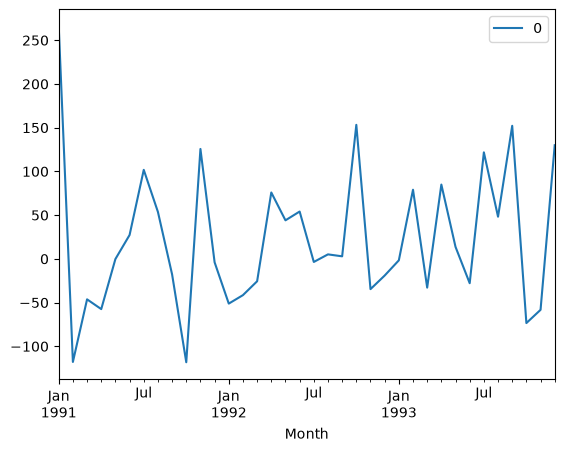

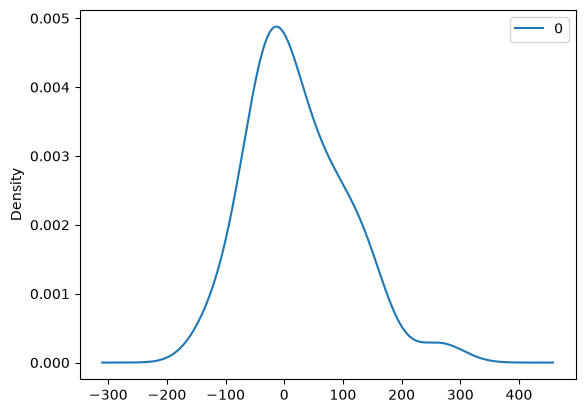

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [4]:
# ARIMA() 함수를 호출하여 sales 데이터셋에 대한 예측

import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

series = pd.read_csv('./data/sales.csv', header=0, index_col=0)
series.index = pd.to_datetime('199' + series.index.astype(str), format='%Y-%m')
series.index = pd.DatetimeIndex(series.index, freq='MS')

model = ARIMA(series, order=(5, 1, 0)) # ARIMA() 함수 호출
model_fit = model.fit()
print(model_fit.summary()) # 모델에 대한 정보 표시
residuals = pd.DataFrame(model_fit.resid) # DataFrame에 모델에 대한 오차 정보를 residuals라는 변수에 저장
residuals.plot()
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773635, expected=325.900000
predicted=372.070411, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690706, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.818


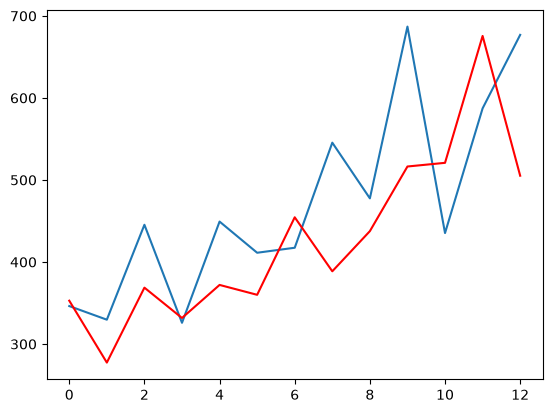

In [5]:
# statsmodels 라이브러리를 이용한 sales 데이터셋 예측

import numpy as np
import pandas as pd
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

series = pd.read_csv('./data/sales.csv', header=0, index_col=0)
series.index = pd.to_datetime('199' + series.index.astype(str), format='%Y-%m')
series.index = pd.DatetimeIndex(series.index, freq='MS')

X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()
for t in range(len(test)):
    model = ARIMA(history, order=(5, 1, 0))
    model_fit = model.fit()
    output = model_fit.forecast()
    yhat = output[0]
    predictions.append(yhat)
    obs = test[t]
    history.append(obs)
    print('predicted=%f, expected=%f' % (yhat, obs))
error = mean_squared_error(test, predictions)
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()